### <b>5차시 꾸미기와 여러 그래프 - 색·마커 · 축과 주석 · subplots · savefig</b>

* 강조할 것 하나만 색을 다르게 하고 나머지는 회색으로 둔다. <b>color</b>·<b>marker</b>·<b>linestyle</b>·<b>linewidth</b>로 선과 막대를 다듬는다.
* <b>tick_params</b>로 눈금 글자를 기울이고, <b>set_ylim</b>·<b>axhline</b>·<b>annotate</b>로 기준선과 설명을 달아 읽는 사람의 시선을 이끈다.
* <b>subplots</b>로 여러 그래프를 한 Figure에 나란히 놓고, <b>savefig</b>로 해상도와 여백을 정해 파일로 저장한다.

* 맨 위 코드 셀은 <b>준비 셀</b>이다. 한글 폰트를 설치해 등록하고, 실습 데이터를 <b>data</b> 폴더에 내려받는다.
  * 내용은 고치지 않고 실행만 한다. 출력에 CSV 파일 이름 두 개가 보이면 끝난 것이다.
  * 세션이 끊겨도 입력한 코드는 남아 있다. 이어서 할 셀을 선택하고 <b>런타임 › 이전 셀 실행</b>을 누르면 준비 셀부터 다시 실행된다.
* 나머지 코드 칸은 강의를 따라 입력한다. 주석(#)은 입력하지 않아도 되고, 앞 셀과 비슷한 코드는 복사해 고친다.

In [1]:
# keep
# 나눔고딕 폰트를 설치한다
!apt-get -qq install -y fonts-nanum > /dev/null
# 실습 데이터를 data 폴더에 내려받는다
!mkdir -p data
!wget -q -nc -P data https://raw.githubusercontent.com/wonguwon/generate_lesson/feature/lesson-subagents/materials/matplotlib-seaborn/data/students.csv https://raw.githubusercontent.com/wonguwon/generate_lesson/feature/lesson-subagents/materials/matplotlib-seaborn/data/cafe_sales.csv
# 설치한 폰트를 Matplotlib에 등록한다
from matplotlib import font_manager
font_manager.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
# 내려받은 파일을 확인한다
!ls data

* 준비 셀 다음 셀에 <b>설정 셀</b>을 입력한다. 1차시에서 정한 그대로다.

In [2]:
# 표를 다루는 pandas와 그래프를 그리는 plt를 불러온다
import pandas as pd
import matplotlib.pyplot as plt

# 그래프의 기본 폰트를 나눔고딕으로 정한다
plt.rcParams['font.family'] = 'NanumGothic'
# 축 눈금의 마이너스를 일반 하이픈으로 바꾼다
plt.rcParams['axes.unicode_minus'] = False

* 오늘도 두 파일을 모두 쓴다. 2차시와 같은 방법으로 읽는다.
  * <b>students</b>: 학생 300명의 생활 습관 설문(가상), 학생 1명 = 1행
  * <b>cafe</b>: 캠퍼스 카페 365일 판매(가상), 하루 = 1행. date 열은 날짜로 읽는다.

In [3]:
# 학생 설문 CSV를 읽어 students에 담는다
students = pd.read_csv('data/students.csv')
# 카페 판매 CSV를 date를 날짜로 읽어 cafe에 담는다
cafe = pd.read_csv('data/cafe_sales.csv', parse_dates=['date'])
# 두 표의 행과 열 수를 출력한다
print(students.shape, cafe.shape)

(300, 12) (365, 14)


#### <b>1) 메뉴별 판매량 선 그래프에서 아메리카노만 강조</b>

* 3차시에서 메뉴 네 개의 일별 판매량을 겹쳐 그렸다. 하루 단위라 선이 촘촘했다.
* 이번에는 <b>groupby</b>로 월마다 메뉴별 판매 잔 수를 더해 12개 값만 남긴다.
  * 열 네 개를 한꺼번에 더하므로 결과는 <b>DataFrame</b>이다. index는 월(year_month), 열은 메뉴다.

In [4]:
# 월마다 메뉴 네 개의 판매 잔 수를 더한다
menu_by_month = cafe.groupby('year_month')[['americano', 'latte', 'ade', 'tea']].sum()
# 월별 메뉴 판매량 표를 본다
menu_by_month

,americano,latte,ade,tea
year_month,,,,
2025-03,4573,2880,1660,1342
2025-04,4793,2697,2475,1151
2025-05,4410,2179,2399,817
2025-06,4046,1854,2611,611
2025-07,1939,753,1559,180
2025-08,1878,695,1567,172
2025-09,4220,1721,3173,486
2025-10,4086,2273,2021,1011
2025-11,3864,2396,1563,1179


* 먼저 3차시처럼 기본 색으로 그린다. 선 네 개가 파랑·주황·초록·빨강으로 모두 비슷하게 눈에 띈다.
  * 무엇을 보라는 그래프인지 그래프만 보고는 알기 어렵다.

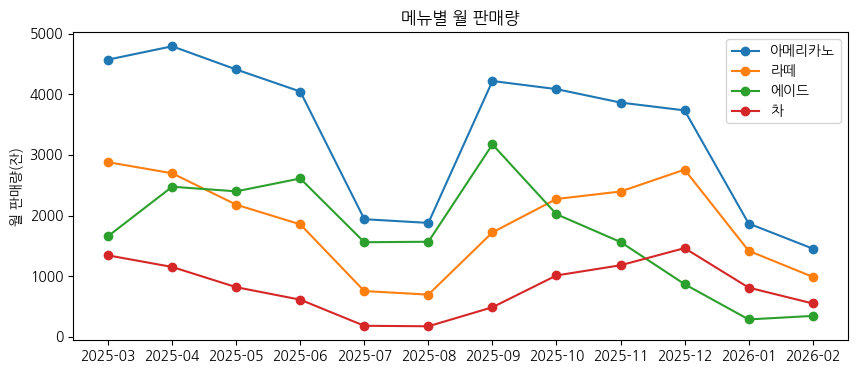

In [5]:
# 가로로 긴 Figure와 Axes를 만든다
fig, ax = plt.subplots(figsize=(10, 4))
# 메뉴 네 개를 기본 색으로 그린다
ax.plot(menu_by_month.index, menu_by_month['americano'], marker='o', label='아메리카노')
ax.plot(menu_by_month.index, menu_by_month['latte'], marker='o', label='라떼')
ax.plot(menu_by_month.index, menu_by_month['ade'], marker='o', label='에이드')
ax.plot(menu_by_month.index, menu_by_month['tea'], marker='o', label='차')
# 제목과 y축 이름을 단다
ax.set_title('메뉴별 월 판매량')
ax.set_ylabel('월 판매량(잔)')
# 범례를 표시한다
ax.legend()
# 그래프를 화면에 보여 준다
plt.show()

* 선의 모양은 plot 안에 인자로 정한다.
  * <b>color</b>: 색. 이름('lightgray', 'tab:blue')이나 <b>HEX</b> 코드('#d62728', 빨강·초록·파랑 세기를 16진수 두 자리씩 적은 색 번호)로 쓴다.
  * <b>marker</b>: 값 자리의 점 모양. 'o' 동그라미, 's' 네모, '^' 세모
  * <b>linestyle</b>: 선 모양. '-' 실선, '--' 끊은 선, ':' 점선, '-.' 점·선
  * <b>linewidth</b>: 선 굵기. 기본 1.5
  * <b>alpha</b>: 4차시 산점도에서 본 투명도. 선에도 똑같이 쓴다.
* 강조 원칙: 보여 줄 선 하나만 진한 색·굵은 선으로, 나머지는 회색으로 둔다.
  * 회색 선 세 개는 linestyle을 다르게 해서 범례로 구분한다.
  * 아메리카노를 마지막에 그려 회색 선 위에 올라오게 한다.
  * 제목에 그래프가 말하려는 결론을 쓴다.

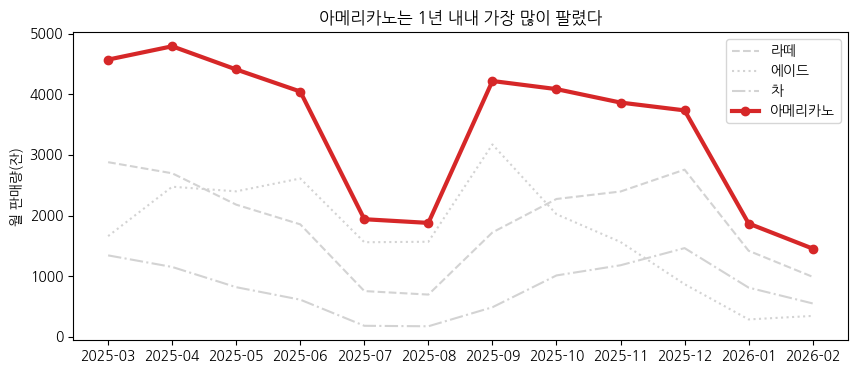

In [6]:
# 가로로 긴 Figure와 Axes를 만든다
fig, ax = plt.subplots(figsize=(10, 4))
# 나머지 메뉴 세 개는 회색 선으로 그린다
ax.plot(menu_by_month.index, menu_by_month['latte'], color='lightgray', linestyle='--', label='라떼')
ax.plot(menu_by_month.index, menu_by_month['ade'], color='lightgray', linestyle=':', label='에이드')
ax.plot(menu_by_month.index, menu_by_month['tea'], color='lightgray', linestyle='-.', label='차')
# 아메리카노만 굵은 빨간 선으로 그린다
ax.plot(menu_by_month.index, menu_by_month['americano'], color='#d62728', marker='o', linewidth=3, label='아메리카노')
# 결론을 제목으로 쓰고 y축 이름을 단다
ax.set_title('아메리카노는 1년 내내 가장 많이 팔렸다')
ax.set_ylabel('월 판매량(잔)')
# 범례를 표시한다
ax.legend()
# 그래프를 화면에 보여 준다
plt.show()

* 그래프에서 읽을 것
  * 빨간 아메리카노 선이 12개월 모두 맨 위에 있다. 가장 많은 달은 2025-04(4,793잔), 가장 적은 달은 2026-02(1,454잔)다.
  * 회색 선은 배경으로 물러나고, 눈이 빨간 선을 먼저 따라간다. 데이터는 그대로이고 색만 바꿨다.

#### <b>2) 전공별 학생 수 막대에서 가장 큰 막대만 강조</b>

* 4차시의 정렬한 전공별 학생 수를 다시 만든다. 작은 값부터 정렬되어 공학(80명)이 마지막에 있다.

In [7]:
# 전공별 학생 수를 세어 작은 값부터 정렬한다
major_count_sorted = students['major'].value_counts().sort_values()
# 정렬한 결과를 본다
major_count_sorted

major
예체능     40
인문      55
자연과학    55
사회과학    70
공학      80
Name: count, dtype: int64

* 막대는 <b>color</b>에 색 하나를 넣으면 모든 막대가 그 색이 되고, 색 <b>리스트</b>를 넣으면 막대마다 색이 따로 칠해진다.
  * 리스트 순서는 막대 순서와 같아야 한다.
* 가장 큰 값만 빨강, 나머지는 회색인 리스트를 만든다.
  * <b>[A if 조건 else B for v in 값들]</b>: 값을 하나씩 꺼내 조건이 맞으면 A, 아니면 B를 담는 파이썬 리스트 문법이다.
  * 조건을 '공학'이 아니라 <b>max()</b>로 써 두면 데이터가 바뀌어도 가장 큰 막대가 칠해진다.

In [8]:
# 가장 큰 값만 빨강, 나머지는 회색으로 정한다
colors = ['#d62728' if v == major_count_sorted.max() else 'lightgray' for v in major_count_sorted.values]
# 만든 색 리스트를 본다
colors

['lightgray', 'lightgray', 'lightgray', 'lightgray', '#d62728']

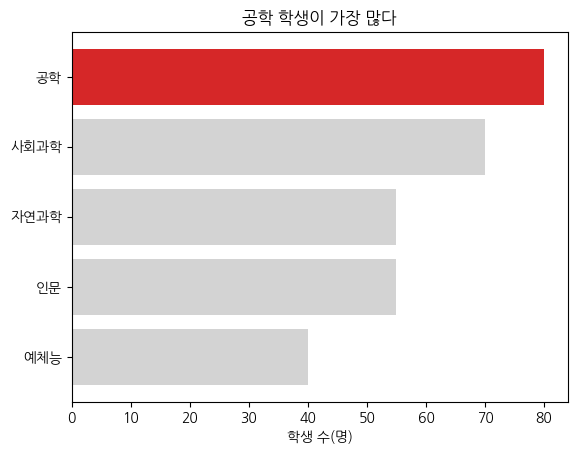

In [9]:
# Figure와 Axes를 만든다
fig, ax = plt.subplots()
# 막대마다 색을 따로 칠해 가로 막대를 그린다
ax.barh(major_count_sorted.index, major_count_sorted.values, color=colors)
# 결론을 제목으로 쓰고 x축 이름을 단다
ax.set_title('공학 학생이 가장 많다')
ax.set_xlabel('학생 수(명)')
# 그래프를 화면에 보여 준다
plt.show()

* 맨 위 공학(80명) 막대만 빨갛고 나머지 네 막대는 회색이다.
* 막대 길이는 4차시와 같다. 색은 순위를 바꾸지 않고, 어디를 먼저 볼지만 정한다.

#### <b>3) 일별 손님 수 그래프에 평균선과 시험 주간 주석 달기</b>

* 먼저 3차시에서 남긴 문제부터 푼다. 기본 크기 종이에 월별 평균 손님 수를 그리면 x축 글자 12개가 겹쳤다.
* <b>ax.tick_params(axis='x', labelrotation=45)</b>: x축 눈금 글자를 45도 기울인다. 종이를 넓히지 않고도 글자가 겹치지 않는다.

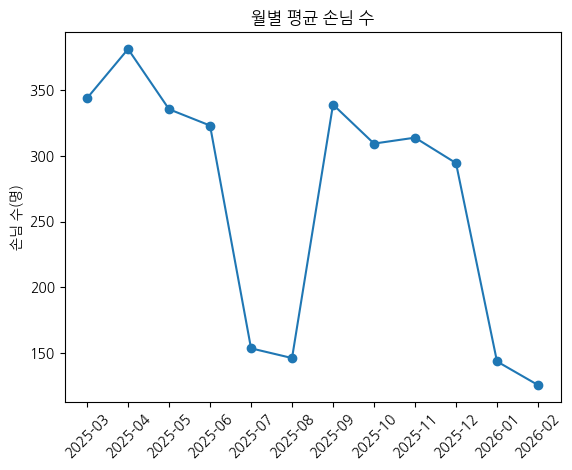

In [10]:
# 월별 평균 손님 수를 구해 소수 둘째 자리로 줄인다
customers_by_month = cafe.groupby('year_month')['customers'].mean().round(2)

# Figure와 Axes를 만든다
fig, ax = plt.subplots()
# 월별 평균을 점과 선으로 그린다
ax.plot(customers_by_month.index, customers_by_month.values, marker='o')
# x축 눈금 글자를 45도 기울인다
ax.tick_params(axis='x', labelrotation=45)
# 제목과 y축 이름을 단다
ax.set_title('월별 평균 손님 수')
ax.set_ylabel('손님 수(명)')
# 그래프를 화면에 보여 준다
plt.show()

* 날짜(datetime) x축은 matplotlib이 눈금 자리와 글자 모양을 저절로 정한다. 직접 정하려면 <b>matplotlib.dates</b>를 쓴다.
  * <b>mdates.MonthLocator()</b>: 눈금을 매달 1일에 하나씩 놓는다. <b>MonthLocator(interval=2)</b>는 두 달마다.
  * <b>mdates.DateFormatter('%Y-%m')</b>: 눈금 글자를 '2025-03' 모양으로 쓴다. %Y는 연도 네 자리, %m은 월 두 자리다.
  * <b>ax.xaxis</b>: Axes의 x축(Axis)이다. 3차시에서 본 Axes 안의 축 객체에 눈금 규칙을 넘긴다.

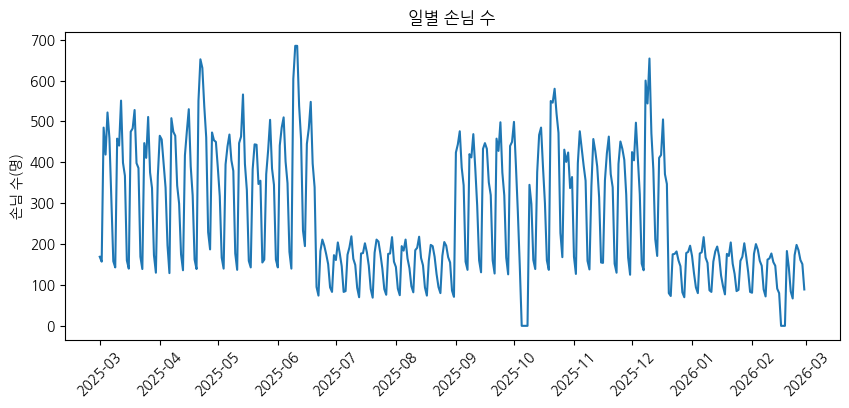

In [11]:
# 날짜 눈금을 정하는 mdates를 불러온다
import matplotlib.dates as mdates

# 가로로 긴 Figure와 Axes를 만든다
fig, ax = plt.subplots(figsize=(10, 4))
# 날짜별 손님 수를 선으로 그린다
ax.plot(cafe['date'], cafe['customers'])
# 눈금을 매달 1일에 놓는다
ax.xaxis.set_major_locator(mdates.MonthLocator())
# 눈금 글자를 연-월 모양으로 쓴다
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
# x축 눈금 글자를 45도 기울인다
ax.tick_params(axis='x', labelrotation=45)
# 제목과 y축 이름을 단다
ax.set_title('일별 손님 수')
ax.set_ylabel('손님 수(명)')
# 그래프를 화면에 보여 준다
plt.show()

* 눈금이 매달 1일에 하나씩, 2025-03부터 2026-03까지 놓인다. 마지막 2026-03 눈금은 마지막 날(2026-02-28) 바로 뒤, 오른쪽 끝 근처에 놓인다.
  * 글자가 year_month 열과 같은 모양이라 월별 그래프와 함께 읽기 쉽다.
* 이제 주석을 달 자리를 찾는다. 2차시의 조건 필터로 시험 주간(exam_week == 1)만 골라 손님이 많은 순으로 본다.

In [12]:
# 시험 주간 행만 골라 exam에 담는다
exam = cafe[cafe['exam_week'] == 1]
# 손님이 많은 순으로 정렬해 위 3행을 본다
exam.sort_values('customers', ascending=False)[['date', 'weekday', 'customers']].head(3)

,date,weekday,customers
101,2025-06-10,화,685
102,2025-06-11,수,685
284,2025-12-10,수,654


* 2025-06-10과 06-11이 둘 다 685명으로 1년 중 가장 많다. 6월 기말시험 주간이다.
  * 이틀이 같은 값이라 '가장 많은 날'은 하나로 정해지지 않는다. 화살표는 둘 중 하루(06-10)를 가리키게 하고, 설명 글에는 날짜 대신 '기말시험 주간'이라고 쓴다.
* 그래프에 기준과 설명을 더한다.
  * <b>ax.set_ylim(0, 800)</b>: y축 범위를 0~800으로 정한다. 아래 기준을 0으로 고정하고, 위에 주석 글자가 들어갈 자리를 만든다.
  * <b>ax.axhline(값)</b>: 그 값 높이에 가로선을 긋는다. 여기서는 365일 평균 손님 수(휴무일 0명 포함 267.95명)다.
  * <b>ax.annotate('글', xy=점 위치, xytext=글 위치, arrowprops=...)</b>: 점 위치에 화살표를 대고 글을 단다.
    * <b>textcoords='offset points'</b>: xytext를 점에서 얼마나 떨어뜨릴지 포인트(약 1/72인치) 단위로 적는다. 날짜 축에서도 숫자 두 개로 쓸 수 있어 편하다.
    * <b>arrowprops=dict(arrowstyle='->')</b>: 글에서 점까지 화살표를 그린다. dict(arrowstyle='->')는 {'arrowstyle': '->'} 사전을 만드는 다른 쓰는 법이다.
    * <b>pd.Timestamp('2025-06-10')</b>: 글자를 날짜 값으로 바꿔 x 위치로 쓴다.
* 앞의 일별 손님 수 셀을 복사해 선 색을 바꾸고 set_ylim·axhline·annotate 줄과 제목·범례만 고친다.

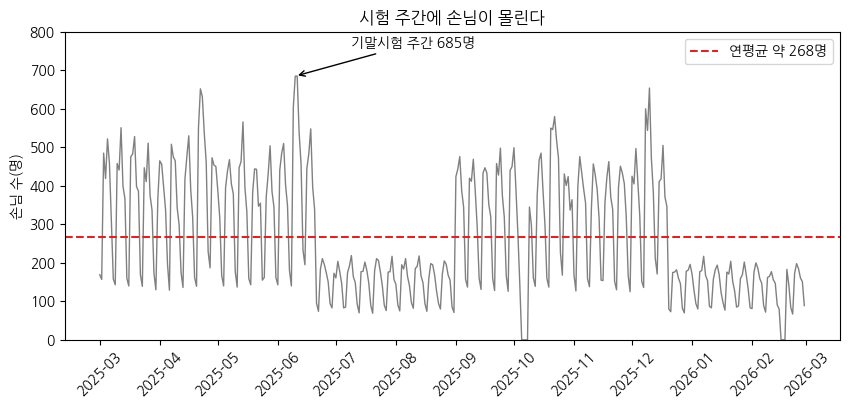

In [13]:
# 가로로 긴 Figure와 Axes를 만든다
fig, ax = plt.subplots(figsize=(10, 4))
# 일별 손님 수를 가는 회색 선으로 그린다
ax.plot(cafe['date'], cafe['customers'], color='gray', linewidth=1)
# y축 범위를 0~800으로 정한다
ax.set_ylim(0, 800)
# 평균 손님 수 높이에 가로 점선을 긋는다
ax.axhline(cafe['customers'].mean(), color='#d62728', linestyle='--', label='연평균 약 268명')
# 6월 10일 자리에 화살표와 설명을 단다
ax.annotate('기말시험 주간 685명', xy=(pd.Timestamp('2025-06-10'), 685),
            xytext=(40, 20), textcoords='offset points',
            arrowprops=dict(arrowstyle='->'))
# 눈금을 매달 1일에 놓는다
ax.xaxis.set_major_locator(mdates.MonthLocator())
# 눈금 글자를 연-월 모양으로 쓴다
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
# x축 눈금 글자를 45도 기울인다
ax.tick_params(axis='x', labelrotation=45)
# 제목과 y축 이름을 단다
ax.set_title('시험 주간에 손님이 몰린다')
ax.set_ylabel('손님 수(명)')
# 범례를 오른쪽 위에 놓는다
ax.legend(loc='upper right')
# 그래프를 화면에 보여 준다
plt.show()

* 그래프에서 읽을 것
  * 빨간 점선(연평균 약 268명)을 기준으로 학기 평일은 위, 주말·방학은 아래에 있다.
  * 1년 중 600명 이상인 날은 7일뿐이고, 모두 시험 주간이다. 시험 주간 네 번(4·6·10·12월) 모두 선이 뾰족하게 솟고, 600명 이상인 날은 4·6·12월에만 있다.
  * 화살표와 글이 6월 기말시험 주간 봉우리를 가리켜, 그래프를 처음 보는 사람도 어디를 봐야 하는지 안다.

#### <b>4) 메뉴 4개 판매량을 2×2로 나란히</b>

* 3차시에서 <b>Figure는 종이, Axes는 칸</b>이라고 했다. 지금까지는 종이 한 장에 칸 하나였다.
* <b>plt.subplots(행, 열)</b>: 종이 한 장을 행×열 칸으로 나눈다. 칸이 여러 개면 두 번째 값은 Axes 하나가 아니라 Axes를 담은 <b>배열</b>이다.
  * 그래서 이름도 ax 대신 <b>axes</b>로 쓴다. <b>axes.shape</b>로 칸 배치를 확인한다.

(2, 2)


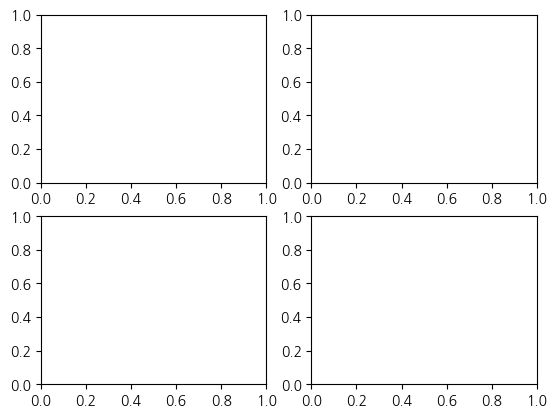

In [14]:
# 종이를 2행 2열 칸으로 나눈다
fig, axes = plt.subplots(2, 2)
# 칸 배치를 출력한다
print(axes.shape)
# 빈 칸을 화면에 보여 준다
plt.show()

* 칸은 <b>axes[행, 열]</b>로 고른다. 번호는 0부터 센다.
  * axes[0, 0] 왼쪽 위, axes[0, 1] 오른쪽 위, axes[1, 0] 왼쪽 아래, axes[1, 1] 오른쪽 아래
* 고른 칸에 지금까지처럼 plot·set_title을 부른다. 1)의 menu_by_month에서 메뉴 하나씩 칸에 그린다.

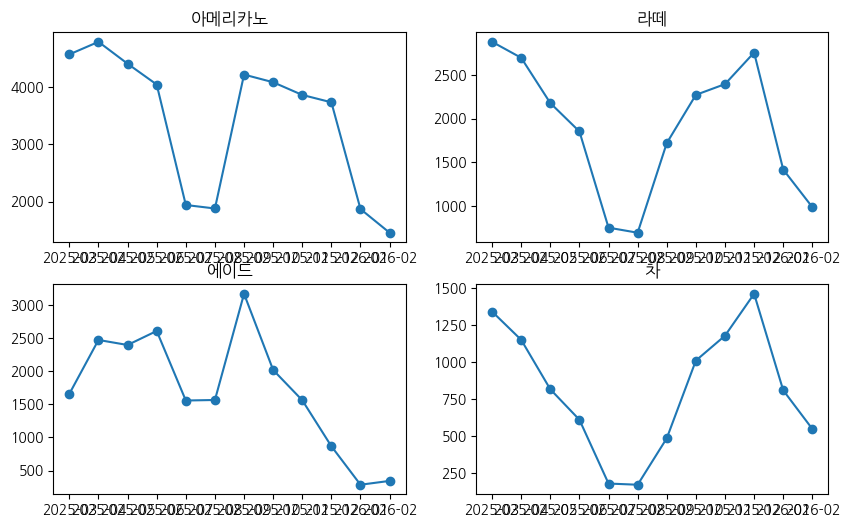

In [15]:
# 2행 2열 칸을 넓은 종이에 만든다
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
# 왼쪽 위 칸에 아메리카노를 그린다
axes[0, 0].plot(menu_by_month.index, menu_by_month['americano'], marker='o')
axes[0, 0].set_title('아메리카노')
# 오른쪽 위 칸에 라떼를 그린다
axes[0, 1].plot(menu_by_month.index, menu_by_month['latte'], marker='o')
axes[0, 1].set_title('라떼')
# 왼쪽 아래 칸에 에이드를 그린다
axes[1, 0].plot(menu_by_month.index, menu_by_month['ade'], marker='o')
axes[1, 0].set_title('에이드')
# 오른쪽 아래 칸에 차를 그린다
axes[1, 1].plot(menu_by_month.index, menu_by_month['tea'], marker='o')
axes[1, 1].set_title('차')
# 그래프를 화면에 보여 준다
plt.show()

* 문제가 세 가지 보인다.
  * 칸마다 y축 범위가 다르다. 차 칸은 y축 맨 위가 1,500, 아메리카노 칸은 4,000을 넘는데도 차 선이 아메리카노 선만큼 크게 오르내리는 것처럼 보인다.
  * x축 글자 12개가 칸마다 겹친다.
  * 위 칸의 x축 글자가 아래 칸 제목과 붙는다.
* 고치는 인자
  * <b>sharey=True</b>: 모든 칸이 y축 범위를 같이 쓴다. 칸끼리 높이를 그대로 비교할 수 있다.
  * <b>sharex=True</b>: x축을 같이 쓴다. 겹치는 눈금 글자는 맨 아래 칸에만 남는다.
  * <b>layout='constrained'</b>: 제목·눈금 글자가 겹치지 않게 칸 사이 간격을 저절로 맞춘다.
  * <b>fig.suptitle('제목')</b>: 칸 전체 위에 Figure 제목을 단다.
* 앞 셀을 복사해 subplots 인자를 바꾸고 tick_params·suptitle 줄만 더한다.

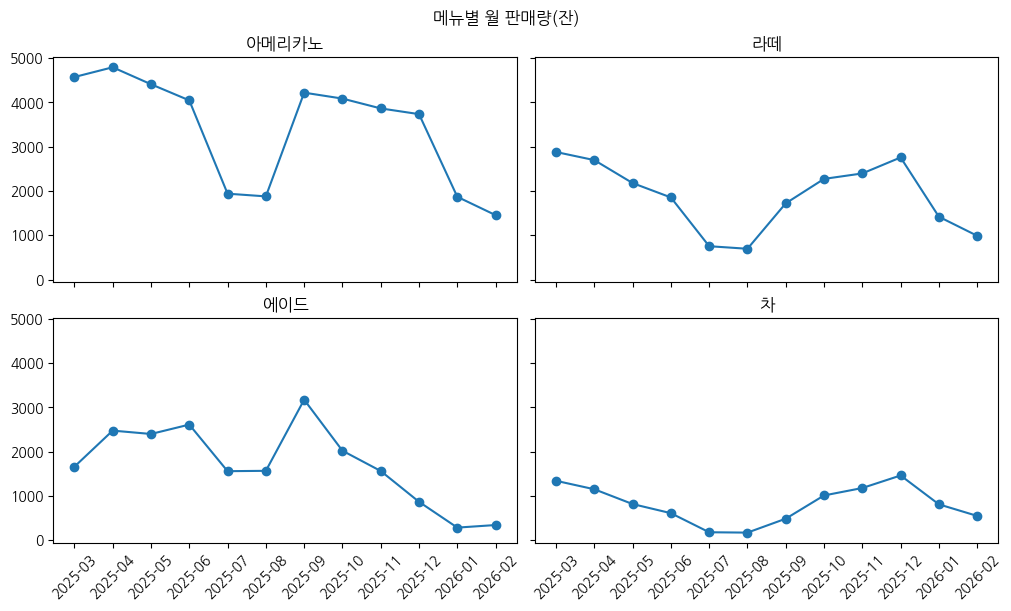

In [16]:
# 두 축을 함께 쓰고 간격을 맞춘 칸을 만든다
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True, layout='constrained')
# 네 칸에 메뉴를 앞 셀과 똑같이 그린다
axes[0, 0].plot(menu_by_month.index, menu_by_month['americano'], marker='o')
axes[0, 0].set_title('아메리카노')
axes[0, 1].plot(menu_by_month.index, menu_by_month['latte'], marker='o')
axes[0, 1].set_title('라떼')
axes[1, 0].plot(menu_by_month.index, menu_by_month['ade'], marker='o')
axes[1, 0].set_title('에이드')
axes[1, 1].plot(menu_by_month.index, menu_by_month['tea'], marker='o')
axes[1, 1].set_title('차')
# 아래 두 칸의 눈금 글자를 기울인다
axes[1, 0].tick_params(axis='x', labelrotation=45)
axes[1, 1].tick_params(axis='x', labelrotation=45)
# 칸 전체 위에 제목을 단다
fig.suptitle('메뉴별 월 판매량(잔)')
# 그래프를 화면에 보여 준다
plt.show()

* 그래프에서 읽을 것
  * 네 칸의 y축이 0~5,000 근처로 같아졌다. 아메리카노가 가장 높고, 차는 가장 많은 달(2025-12, 1,462잔)도 아메리카노의 가장 적은 달(2026-02, 1,454잔)과 비슷한 높이다.
  * 에이드는 9월(3,173잔)에 가장 높고 1월(285잔)에 가장 낮다. 차는 12월에 가장 높고 8월(172잔)에 가장 낮다. 계절에 따라 반대로 움직인다.
* 칸마다 범위가 다르면 모양(언제 오르내리는지)을, 범위가 같으면 크기(얼마나 많은지)를 비교하기 좋다. 무엇을 비교할지에 따라 sharey를 고른다.

#### <b>5) 막대·산점도·히스토그램을 1×3으로 한 장에</b>

* 4차시의 세 그래프를 종이 한 장에 나란히 놓는다. 수면 시간은 4차시처럼 빈 값을 빼 둔다.

In [17]:
# 빈 값을 뺀 수면 시간을 sleep에 담는다
sleep = students['sleep_hours'].dropna()
# 남은 학생 수를 본다
len(sleep)

285

* <b>plt.subplots(1, 3)</b>: 1행 3열. 한 줄짜리 배치는 axes가 1차원 배열이라 <b>axes[0]</b>, <b>axes[1]</b>, <b>axes[2]</b>처럼 번호 하나로 고른다.
  * axes[0, 0]처럼 두 번호를 쓰면 IndexError가 난다.
* 칸마다 다른 종류의 그래프를 그려도 된다. 그리는 함수는 4차시와 같고 ax 자리만 axes[번호]로 바뀐다.
  * 왼쪽 막대에는 2)의 colors를 그대로 넣는다.

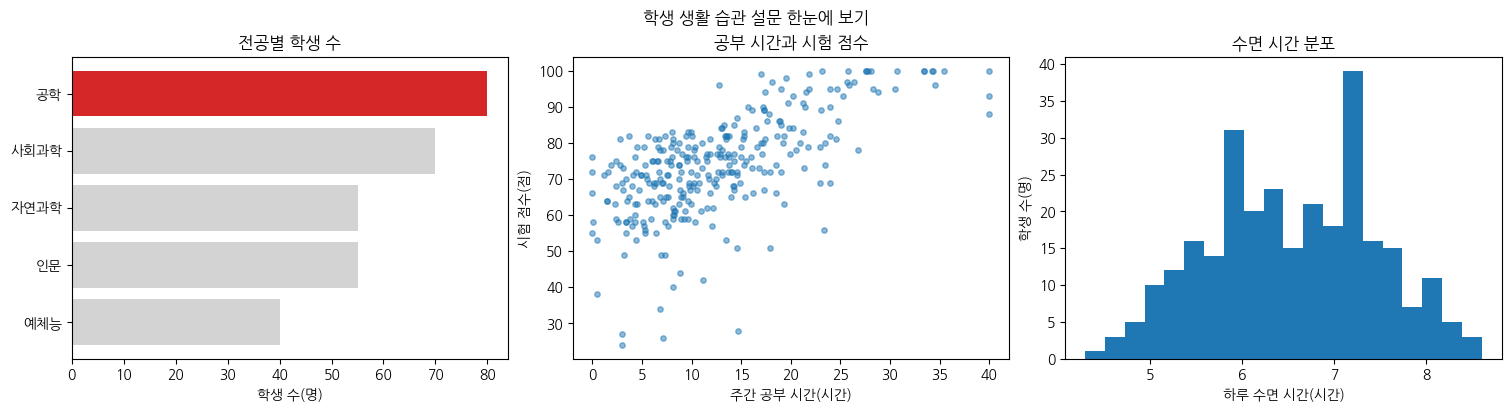

In [18]:
# 1행 3열 칸을 옆으로 넓게 만든다
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
# 왼쪽 칸에 전공별 학생 수 막대를 그린다
axes[0].barh(major_count_sorted.index, major_count_sorted.values, color=colors)
# 왼쪽 칸의 제목과 x축 이름을 단다
axes[0].set_title('전공별 학생 수')
axes[0].set_xlabel('학생 수(명)')
# 가운데 칸에 공부 시간과 점수 산점도를 그린다
axes[1].scatter(students['study_hours'], students['exam_score'], s=15, alpha=0.5)
# 가운데 칸의 제목과 축 이름을 단다
axes[1].set_title('공부 시간과 시험 점수')
axes[1].set_xlabel('주간 공부 시간(시간)')
axes[1].set_ylabel('시험 점수(점)')
# 오른쪽 칸에 수면 시간 히스토그램을 그린다
axes[2].hist(sleep, bins=20)
# 오른쪽 칸의 제목과 축 이름을 단다
axes[2].set_title('수면 시간 분포')
axes[2].set_xlabel('하루 수면 시간(시간)')
axes[2].set_ylabel('학생 수(명)')
# 칸 전체 위에 제목을 단다
fig.suptitle('학생 생활 습관 설문 한눈에 보기')
# 그래프를 화면에 보여 준다
plt.show()

* 세 칸은 비교·관계·분포라는 서로 다른 질문에 답한다. 축의 단위가 달라 sharey는 쓰지 않았다.
* 한 장에 모으면 보고서·발표 자료에 그림 하나로 넣을 수 있다. 저장하는 방법은 6)에서 본다.

#### <b>6) 4)의 그림을 png로 저장하고 폴더에서 열어 보기</b>

* <b>fig.savefig('경로')</b>: Figure를 파일로 저장한다. 확장자(.png, .svg)로 파일 형식이 정해진다.
* savefig는 폴더를 만들어 주지 않는다. 없는 폴더에 저장하면 FileNotFoundError가 난다.
  * <b>os.makedirs('output', exist_ok=True)</b>: data 폴더가 있는 Colab 작업 폴더에 output 폴더를 만든다. 이미 있으면 그냥 넘어간다.

In [19]:
# 폴더를 다루는 os 모듈을 불러온다
import os

# output 폴더를 만든다. 이미 있으면 넘어간다
os.makedirs('output', exist_ok=True)

* 4)의 2×2 그림을 다시 그리고, <b>plt.show() 앞에서</b> 저장한다.
  * <b>dpi=200</b>: 1인치에 점 200개. 숫자가 클수록 확대해도 선명하지만 파일이 커진다.
  * <b>bbox_inches='tight'</b>: 그림 둘레의 빈 여백을 잘라 내고 글자가 잘리지 않게 저장한다.
  * 같은 그림을 .svg로도 저장해 두 형식을 비교한다.
* 4)의 마지막 그림 셀을 복사해 savefig 두 줄만 더한다.

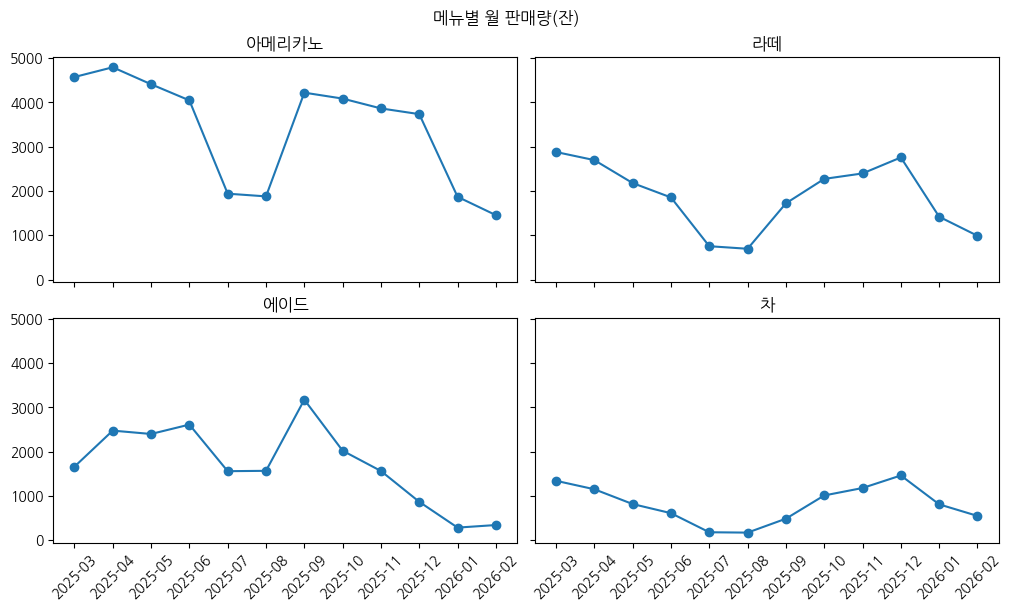

In [20]:
# 4)의 2×2 그림을 다시 그린다
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True, layout='constrained')
axes[0, 0].plot(menu_by_month.index, menu_by_month['americano'], marker='o')
axes[0, 0].set_title('아메리카노')
axes[0, 1].plot(menu_by_month.index, menu_by_month['latte'], marker='o')
axes[0, 1].set_title('라떼')
axes[1, 0].plot(menu_by_month.index, menu_by_month['ade'], marker='o')
axes[1, 0].set_title('에이드')
axes[1, 1].plot(menu_by_month.index, menu_by_month['tea'], marker='o')
axes[1, 1].set_title('차')
axes[1, 0].tick_params(axis='x', labelrotation=45)
axes[1, 1].tick_params(axis='x', labelrotation=45)
fig.suptitle('메뉴별 월 판매량(잔)')
# 해상도와 여백을 정해 png로 저장한다
fig.savefig('output/menu.png', dpi=200, bbox_inches='tight')
# 같은 그림을 svg로도 저장한다
fig.savefig('output/menu.svg', bbox_inches='tight')
# 그래프를 화면에 보여 준다
plt.show()

* 저장된 파일을 확인한다.
  * <b>os.listdir('output')</b>: 폴더 안 파일 이름 목록
  * <b>os.path.getsize(경로)</b>: 파일 크기(바이트)
  * <b>plt.imread(경로).shape</b>: png를 읽어 (세로 픽셀, 가로 픽셀, 색 채널 수)를 본다. 10×6인치에 dpi 200이면 약 2000×1200 픽셀이고, 여백을 잘라 조금 달라진다.
* 이 셀을 다시 실행하면 아래에서 만드는 blank.png도 목록에 함께 나온다.
* 파일은 왼쪽 파일 탭의 output 폴더에 생긴다. menu.png를 더블클릭해 열어 보고, 확대해도 글자가 선명한지 본다.
  * 세션이 끝나면 파일이 사라지니 필요하면 내려받는다.

In [21]:
# output 폴더의 파일 이름을 출력한다
print(sorted(os.listdir('output')))
# 두 파일의 크기(바이트)를 출력한다
print(os.path.getsize('output/menu.png'), os.path.getsize('output/menu.svg'))
# png의 세로·가로 픽셀과 색 채널 수를 출력한다
print(plt.imread('output/menu.png').shape)

['menu.png', 'menu.svg']
129219 83573
(1223, 2022, 4)


* <b>plt.show()</b>가 끝나면 그림이 화면으로 나가고 '지금 그리는 Figure'가 비워진다.
  * 그 뒤에 <b>plt.savefig()</b>를 부르면 빈 새 Figure가 저장된다. 아래 셀은 일부러 순서를 바꿔 본 것이다.

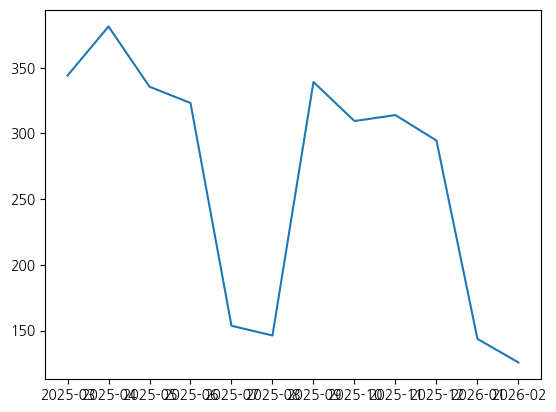

<Figure size 640x480 with 0 Axes>

In [22]:
# Figure와 Axes를 만든다
fig, ax = plt.subplots()
# 월별 평균 손님 수를 선으로 그린다
ax.plot(customers_by_month.index, customers_by_month.values)
# 그래프를 화면에 보여 준다
plt.show()
# 화면에 보여 준 뒤에 저장한다
plt.savefig('output/blank.png')

* 셀 아래에 <b>&lt;Figure size 640x480 with 0 Axes&gt;</b>가 찍힌다. plt.savefig가 칸이 하나도 없는 새 Figure를 저장했다는 뜻이다.
* blank.png를 열면 아무것도 없는 흰 그림이다. 파일 크기도 menu.png보다 훨씬 작다.
* 저장 줄은 항상 plt.show() <b>앞</b>에 두고, plt 대신 <b>fig.savefig</b>처럼 저장할 Figure의 이름으로 부른다.

In [23]:
# blank.png의 크기(바이트)를 출력한다
print(os.path.getsize('output/blank.png'))
# 이미지 값의 최솟값을 출력한다
print(plt.imread('output/blank.png').min())

2398
1.0


* 이미지 값의 최솟값이 1.0이면 모든 점이 흰색이라는 뜻이다. 그래프 선이 하나도 저장되지 않았다.
* 오늘 정리: <b>색은 강조, 축은 기준, 배치는 비교</b>. 꾸미기는 예쁘게가 아니라 읽기 쉽게 하는 일이다.